# ♟️ Chess Numba — 新舊引擎錦標賽對戰 (Colab Tournament Runner)

本 Notebook 用於在 Google Colab 雲端高並行 CPU 環境下，讓 **新版本引擎 (Candidate / New)** 與 **基準版本引擎 (Baseline / Old)** 進行成對換先（Color-swapped Pairs）錦標賽對抗：

### 🎯 本輪對抗設定 (實驗 E85：SEE 子力價值統一 MG_MATERIAL_VALUES + 門檻等比例縮放與 SPSA 納入)
* **Engine 1 (New / Candidate)**: `chess_engine/classical`
  * ✅ **SEE 子力價值統一**：`SEE_PIECE_VALUES` 直接引用 `MG_MATERIAL_VALUES` (`[100, 347, 364, 572, 1170, 20000]`)，消除 ProbCut SEE 過濾器、Capture LMR 與評估尺度的落差。
  * ✅ **SEE 相關門檻與歷史斜率等比例縮放 ($	imes 1.134$)**：
    1. `PRUNING_CAPTURE_SEE_MARGIN`: `-102` $\to$ **`-116`** (Slot `TUNE_SEE_CAP_MARGIN = 4`)
    2. `PRUNING_QUIET_SEE_MARGIN`: `-32` $\to$ **`-36`** (Slot `TUNE_SEE_QUIET_MARGIN = 5`)
    3. `QS_SEE_THRESHOLD`: `-80` $\to$ **`-91`** (Slot `TUNE_QS_SEE = 14`)
    4. `CHECK_SEE_THRESHOLD`: `-75` $\to$ **`-85`** (Slot `TUNE_CHECK_SEE_THR = 42`)
    5. `CAP_SEE_CAPTHIST_NUM`: `34` $\to$ **`39`** (Slot `TUNE_CAP_SEE_HIST_NUM = 43`)
  * ✅ **Runtime SPSA 完整納入**：`SearchContext.tune` 擴充至 44 槽，熱路徑改讀動態參數，並提供專屬 `--profile see`。
* **Engine 2 (Old / Baseline)**: `chess_engine/classical_old`（E84 採納基線，包含 SEE 核心漏洞修復與前置合法性過濾，但維持舊獨立 `SEE_PIECE_VALUES = [100, 320, 330, 500, 900, 20000]` 與舊版門檻）
* **時控模式**: 固定節點（400,000 nodes 長時控）
* **對戰規格**: 600 局（300 對開局交換白黑），64MB 轉置表，開局庫 `data/openings.epd`
* **統計模型**: SPRT（Sequential Probability Ratio Test）與 Elo 95% 置信區間


In [1]:
# =====================================================================
# 步驟 1: 檢視 Colab 雲端硬體規格與 CPU 核心數
# =====================================================================
!lscpu | grep "Model name\|Socket\|Thread\|NUMA\|CPU(s)"
!free -h
!python3 --version


CPU(s):                                  8
On-line CPU(s) list:                     0-7
Model name:                              AMD EPYC 7B12
Thread(s) per core:                      2
Socket(s):                               1
NUMA node(s):                            1
NUMA node0 CPU(s):                       0-7
               total        used        free      shared  buff/cache   available
Mem:            50Gi       1.4Gi        47Gi       2.2Mi       2.7Gi        49Gi
Swap:             0B          0B          0B
Python 3.13.18


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [2]:
# =====================================================================
# 步驟 2: 載入代碼庫與相依套件
# 支援方式 A：直接從 GitHub 倉庫拉取最新分支
# 支援方式 B：若您上傳了 zip 或放在 Google Drive，亦可解壓至 /content/chess_numba
# =====================================================================
import os

repo_url = "https://github.com/b08203031/chess_numba.git"
branch = "feat-initial-bitboard-setup"

if not os.path.exists('/content/chess_numba'):
    %cd /content
    !git clone -b {branch} {repo_url}

%cd /content/chess_numba
# 若代碼庫已存在，拉取最新變更
!git fetch origin {branch}
!git checkout -f {branch}
!git reset --hard origin/{branch}
!git clean -fd

# 安裝必要相依套件
!pip install -q numba chess numpy matplotlib scipy
print("\n🎉 環境與相依套件安裝完畢！")


/content
Cloning into 'chess_numba'...
remote: Enumerating objects: 4968, done.
remote: Counting objects: 100% (274/274), done.
remote: Compressing objects: 100% (141/141), done.
remote: Total 4968 (delta 195), reused 183 (delta 132), pack-reused 4694 (from 2)
Receiving objects: 100% (4968/4968), 208.39 MiB | 35.05 MiB/s, done.
Resolving deltas: 100% (3495/3495), done.
/content/chess_numba
From https://github.com/b08203031/chess_numba
 * branch            feat-initial-bitboard-setup -> FETCH_HEAD
Already on 'feat-initial-bitboard-setup'
Your branch is up to date with 'origin/feat-initial-bitboard-setup'.
HEAD is now at d6a8149 完成一次全部的調參
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done

🎉 環境與相依套件安裝完畢！


In [ ]:
# =====================================================================
# 步驟 3: 嚴格核對新舊引擎代碼差異（驗證 Candidate vs Baseline）
# =====================================================================
import sys
from pathlib import Path

# 1) 清理 Python 模組記憶體快取
for m in list(sys.modules.keys()):
    if 'chess_engine' in m or 'tune_search' in m:
        del sys.modules[m]
!python -m tuner.sync_constants_snapshot
# 2) 顯示新舊版本差異（確認 classical vs classical_old 確實包含本次修改）
print("=" * 60)
print("🔍 新舊引擎邏輯代碼差異比對 (classical vs classical_old)：")
print("=" * 60)
!python tools/sync_classical_old.py --diff

# 3) 快速合約測試 (確保 JIT 與核心介面運作正常)
print("\n" + "=" * 60)
print("🔥 執行單元合約測試：")
print("=" * 60)
!python -m unittest tests/test_search_core_contracts.py


Unchanged tuner/constants_snapshot.py
🔍 新舊引擎邏輯代碼差異比對 (classical vs classical_old)：

[!] Differences found in constants.py:
--- classical_old/constants.py
+++ classical/constants.py
@@ -40,8 +40,8 @@
 #   SF types.h → N 367/401, B 387/430, R 599/648, Q 1192/1259.
 # Passed / path / prox use the same *100/213 so pass/N matches SF relative strength.
 # Index: PAWN, KNIGHT, BISHOP, ROOK, QUEEN, KING
-MG_MATERIAL_VALUES = np.array([100, 347, 364, 572, 1170, 0], dtype=np.int32)
-EG_MATERIAL_VALUES = np.array([117, 422, 437, 690, 1284, 0], dtype=np.int32)
+MG_MATERIAL_VALUES = np.array([100, 348, 364, 572, 1171, 0], dtype=np.int32)
+EG_MATERIAL_VALUES = np.array([117, 421, 438, 692, 1287, 0], dtype=np.int32)
 # =============================================================================
 # --- Game Phase Calculation (SF11 npm taper) / 遊戲階段計算 ---
 # =============================================================================
@@ -79,19 +79,19 @@
 
 PST_MG = np.array([
     [0, 0, 0, 0, 0, 0, 

In [5]:
# =====================================================================
# 步驟 4: 設定對戰參數並啟動錦標賽
# =====================================================================
import multiprocessing

# 自動偵測可用的 CPU 核心數 (留 1 核給主行程排程)
cpu_count = multiprocessing.cpu_count()
auto_concurrency = max(1, cpu_count - 1)

# --- 參數設定 ---
GAMES = 1000                 # 對局總數 (必須為偶數；400 局可獲穩健 Elo 95% CI)
NODES = 100000              # 每步節點預算 (300k 長時控；快速測試可改為 50000)
TT_MB = 64                  # 每個 Worker 的轉置表大小 (MB)
CONCURRENCY = auto_concurrency  # 平行對局數 (例如 7 或 11)

print("=" * 60)
print(f"♟️ 錦標賽參數配置：")
print(f"  總局數: {GAMES} 局 ({GAMES // 2} 對成對換先開局)" 
      f"  時控: {NODES:,} nodes/move" 
      f"  並行 Worker: {CONCURRENCY}" 
      f"  轉置表: {TT_MB} MB / context")
print("=" * 60)

%cd /content/chess_numba
!python tools/tournament.py --games {GAMES} --nodes {NODES} --concurrency {CONCURRENCY} --tt-mb {TT_MB} --seed 31415926


♟️ 錦標賽參數配置：
  總局數: 1000 局 (500 對成對換先開局)  時控: 100,000 nodes/move  並行 Worker: 7  轉置表: 64 MB / context
/content/chess_numba
Backend: inprocess; workers=7; TT=64 MB/context; openings=34700; seed=31415926
Adjudication: win >= 500 cp (10 plies), draw <= 8 cp (12 plies after move 40)
JIT plan: classical once + classical_old once; worker contexts share compiled code.
Warm-up: Kiwipete depth 14 for each Python/Numba backend, then one complete startpos game at depth 1 (all results discarded).
[pool] allocate worker 1/7
[warmup] New: Kiwipete depth=14...
info depth 1 score cp 59 nodes 453 nps 884 hashfull 0.0% time 512 pv e2a6
info depth 2 score cp 59 nodes 850 nps 1077 hashfull 0.0% time 789 pv e2a6 b4c3
info depth 3 score cp -8 nodes 2663 nps 3365 hashfull 0.0% time 791 pv e2a6 b4c3 d2c3
info depth 4 score cp -8 nodes 3010 nps 3801 hashfull 0.0% time 791 pv e2a6 b4c3 d2c3 h3g2
info depth 5 score cp -103 nodes 7974 nps 9988 hashfull 0.0% time 798 pv e2a6 b4c3 d2c3 e6d5 e4d5
info depth 6 score cp

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [6]:
# =====================================================================
# 步驟 5: 產出統計報告與搜尋剪枝指標診斷
# =====================================================================
%cd /content/chess_numba
!python tournament_analysis/統計數據.py
!python tournament_analysis/parse_search_stats.py

# report_path = Path("tournament_analysis/game_stats_report.txt")
# if report_path.exists():
#     print("\n" + "=" * 60)
#     print("📊 對戰統計結果報告 (Game Stats Report)：")
#     print("=" * 60)
#     print(report_path.read_text(encoding='utf-8'))

# search_report_path = Path("tournament_analysis/search_stats_report.txt")
# if search_report_path.exists():
#     print("\n" + "=" * 60)
#     print("🔬 搜尋樹指標與剪枝診斷報告 (Search Stats Report)：")
#     print("=" * 60)
#     print(search_report_path.read_text(encoding='utf-8'))


/content/chess_numba
PGN: /content/chess_numba/tournament_analysis/tournament_results.pgn
Detected engines: ['New', 'Old']
Target: New
========== 引擎對戰深度分析報告 (New) ==========

來源 PGN: /content/chess_numba/tournament_analysis/tournament_results.pgn
序列順序: numeric Round order (PGN completion order reordered)
日期分佈: {'2026.11.01': 1000}
White 名稱: Counter({'New': 500, 'Old': 500})
Black 名稱: Counter({'Old': 500, 'New': 500})

[1. 總體戰績與 Elo 表現]
總對局數 : 1000 局
戰績統計 : 勝 272 | 和 508 | 負 220
勝率(含和) : 52.60%
和局率 : 50.80%
相對 Elo 變化 : 18.08
95% 信賴區間 : [2.85, 33.39]
CI 單位 : color-swapped pair clustered (n=500 independent units)
  ✅ 95% 信心：明顯強於對手（CI 下界 > 0）


[2. 先手優勢與執色分析]
持白勝率 : 54.60% (勝:150 和:246 負:104)
持黑勝率 : 50.60% (勝:122 和:262 負:116)
賽局總體白方勝率 : 52.00%
卡方 p-value : 1.3260e-01


[3. 開局策略分析 (Top 5)]
【持白主流開局】
  - O-O: n=43 勝率 56.98% (W14 D21 L8)
  - a4: n=19 勝率 44.74% (W3 D11 L5)
  - Nc3: n=17 勝率 58.82% (W5 D10 L2)
  - h3: n=16 勝率 56.25% (W6 D6 L4)
  - Be3: n=12 勝率 50.00% (W3 D6 L3)
【持黑面對的主流開局】
  - 面對


📈 累積分數曲線 (Cumulative Score)：


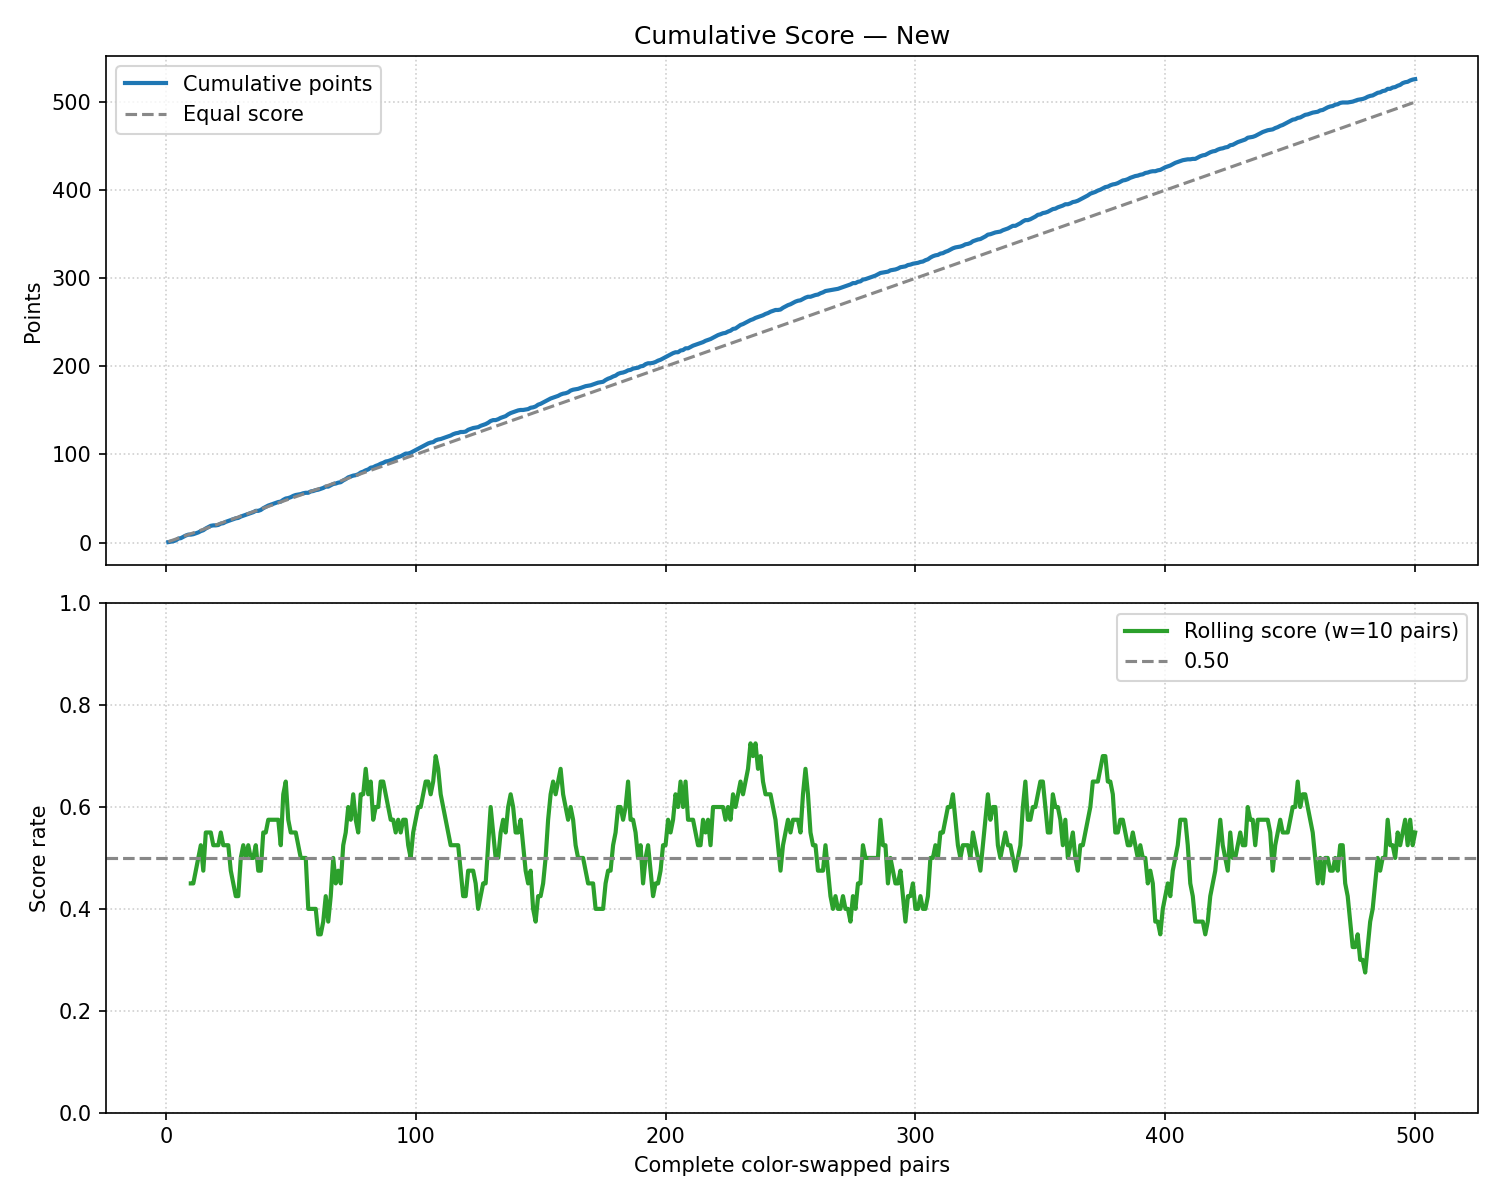


📈 Elo 置信區間收斂圖 (Elo CI)：


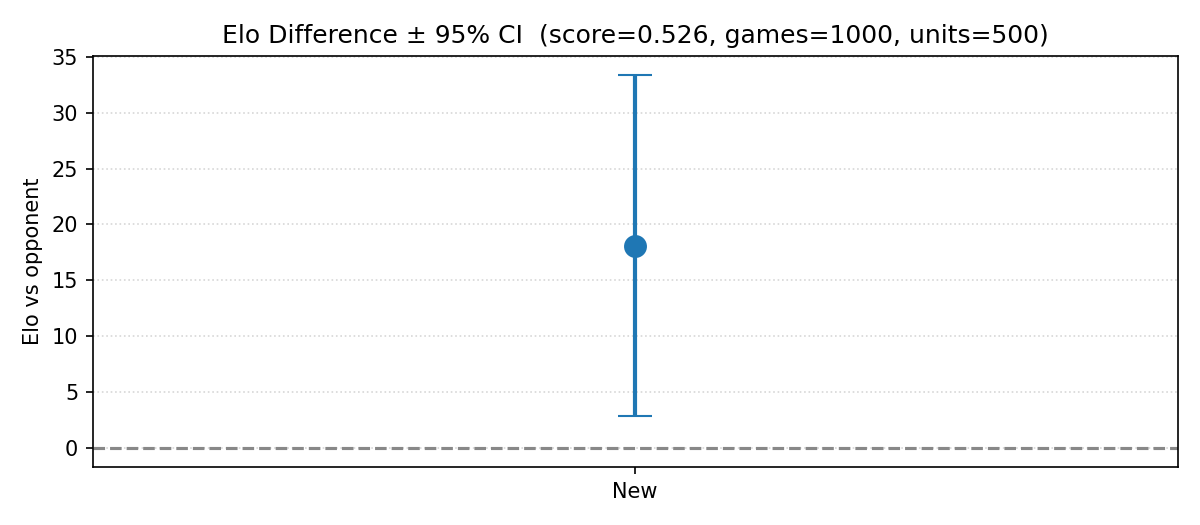


📈 每手搜尋深度 (Depth per Move)：


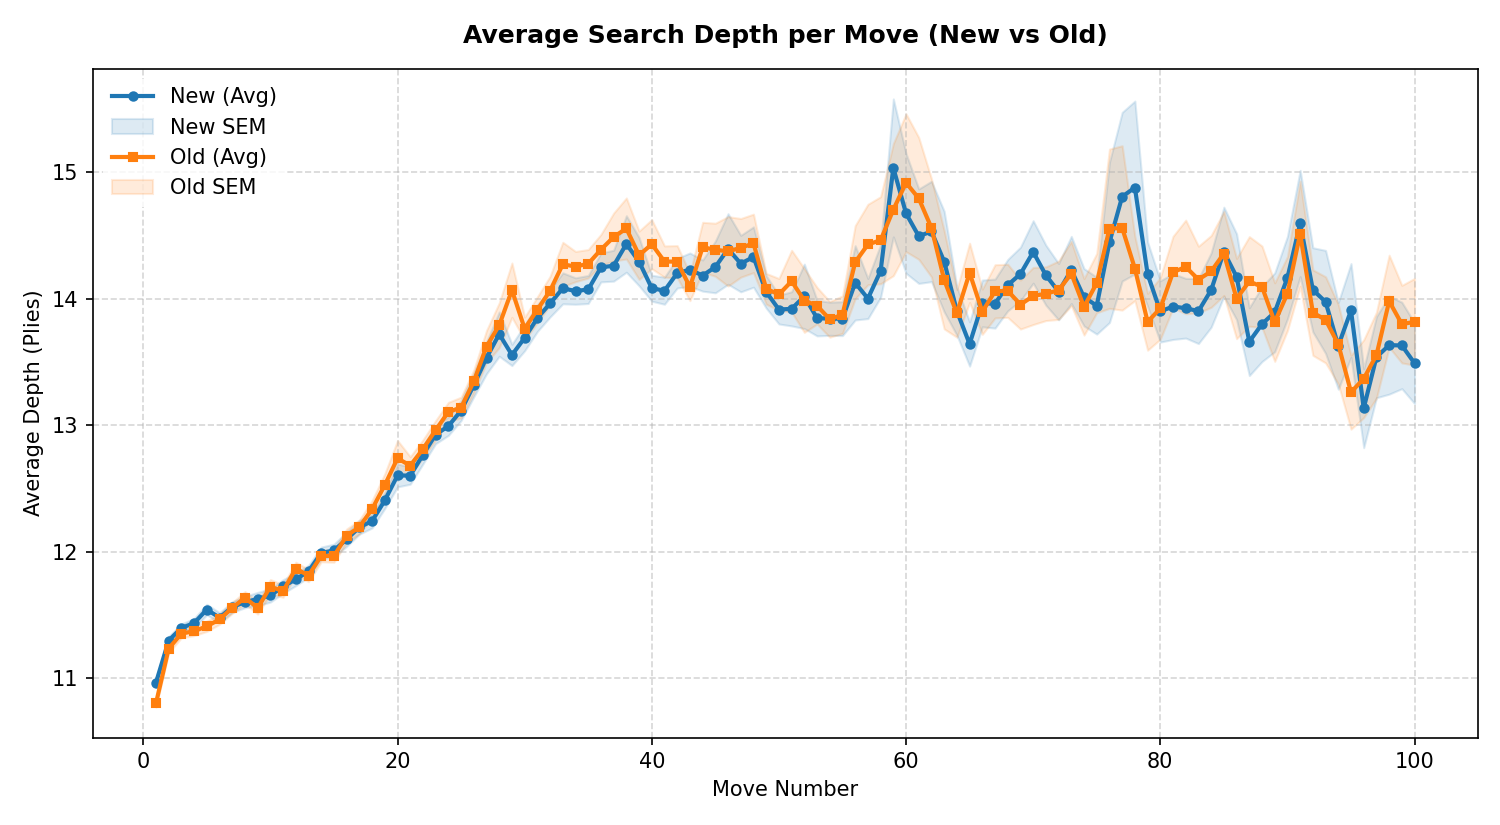


📈 同深度節點比例分佈 (Same-Depth Node Ratio)：


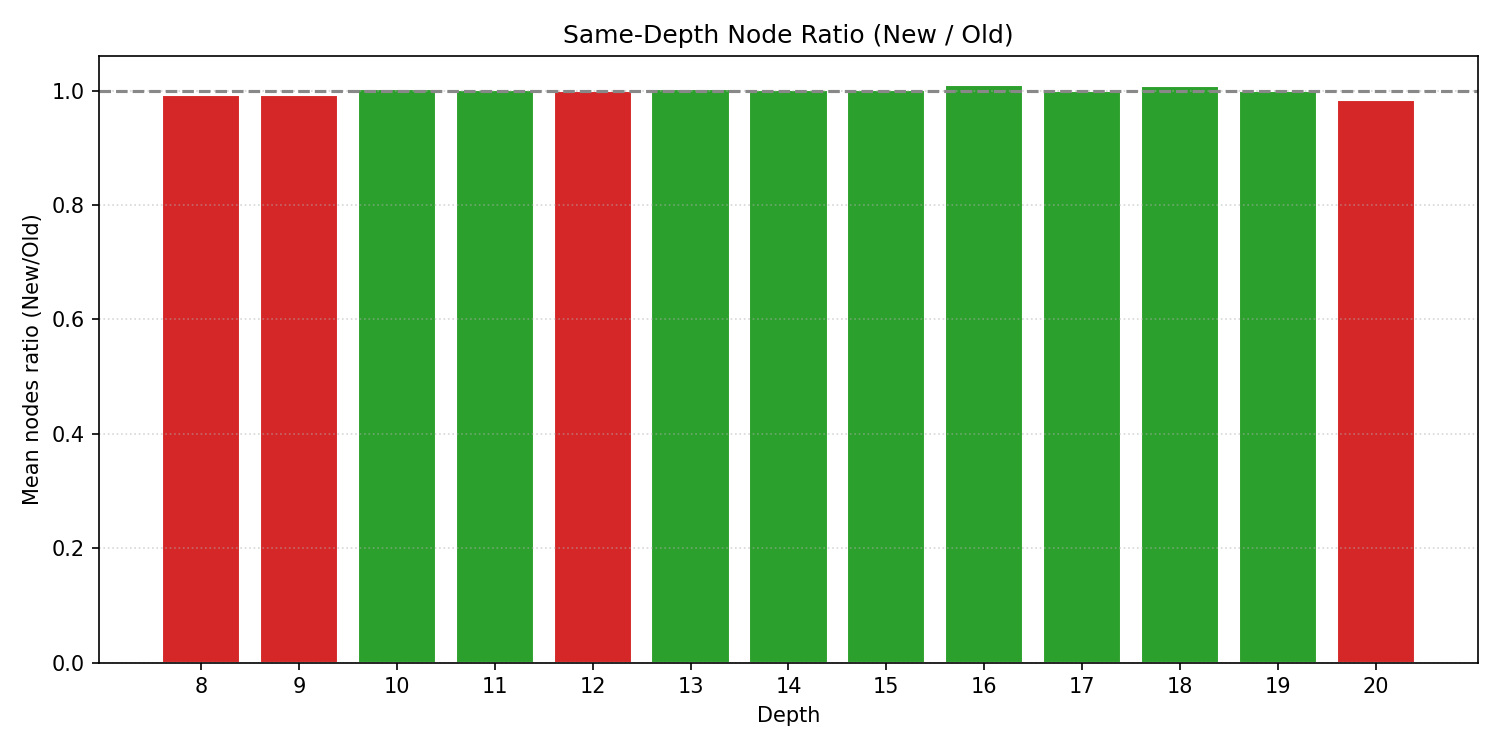


📈 平均節點數 vs 深度散佈 (Avg Nodes vs Depth)：


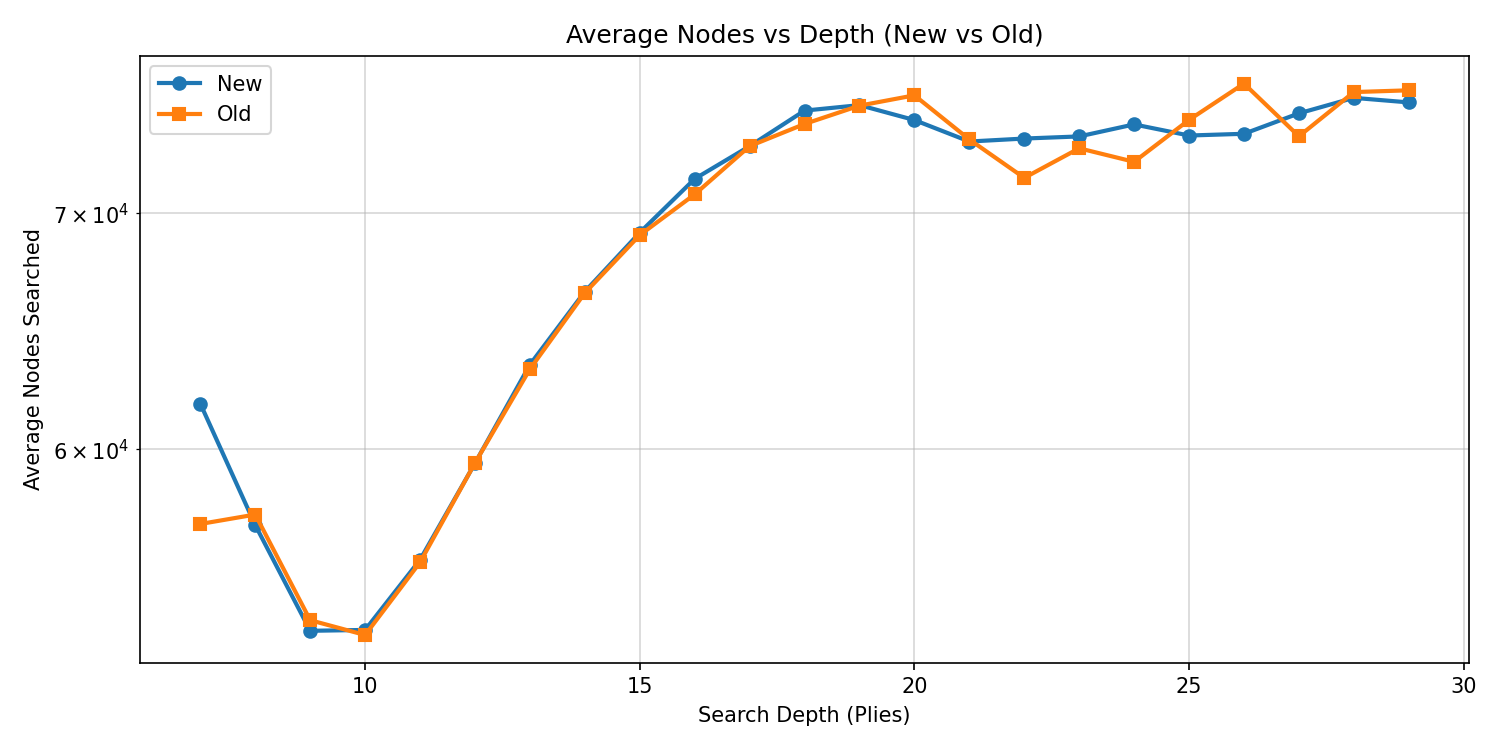


📈 黑白勝負分佈 (WDL by Color)：


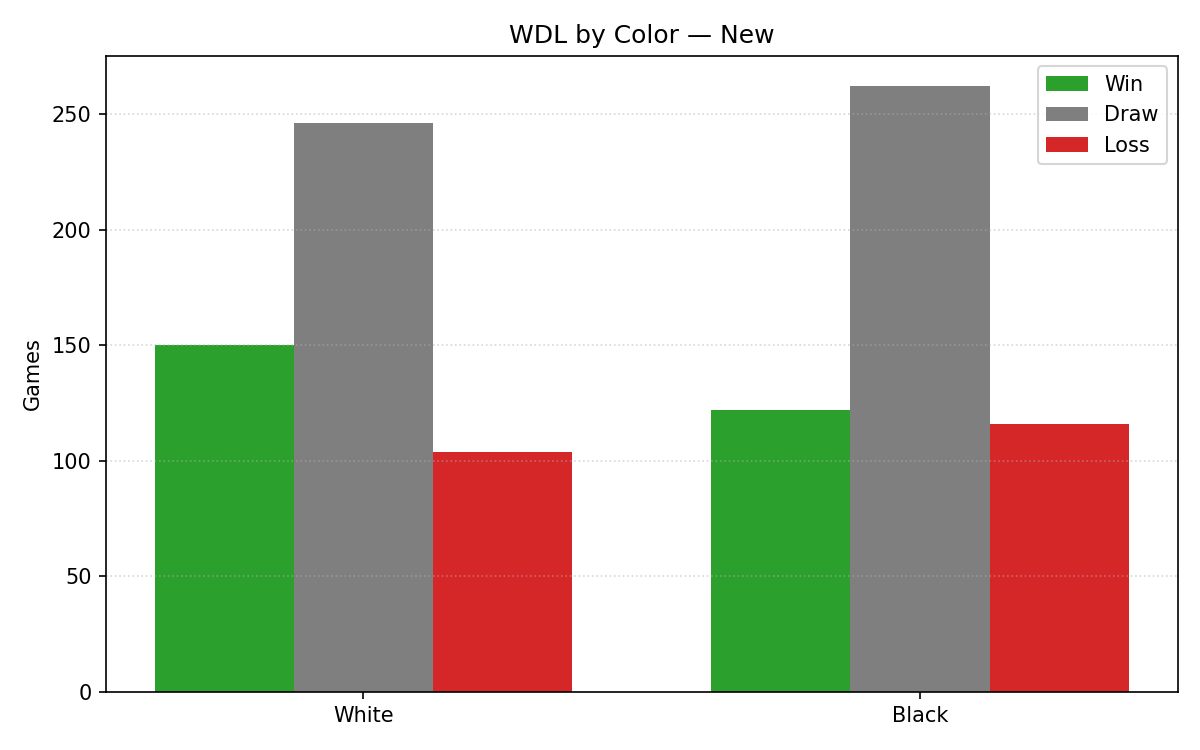

In [7]:
# =====================================================================
# 步驟 6: 視覺化關鍵圖表展示
# =====================================================================
import os
from IPython.display import Image, display

charts = [
    ("累積分數曲線 (Cumulative Score)", "tournament_analysis/cumulative_score.png"),
    ("Elo 置信區間收斂圖 (Elo CI)", "tournament_analysis/elo_ci.png"),
    ("每手搜尋深度 (Depth per Move)", "tournament_analysis/depth_per_move.png"),
    ("同深度節點比例分佈 (Same-Depth Node Ratio)", "tournament_analysis/same_depth_node_ratio.png"),
    ("平均節點數 vs 深度散佈 (Avg Nodes vs Depth)", "tournament_analysis/avg_nodes_vs_depth.png"),
    ("黑白勝負分佈 (WDL by Color)", "tournament_analysis/wdl_by_color.png"),
]

for title, path in charts:
    if os.path.exists(path):
        print(f"\n📈 {title}：")
        display(Image(filename=path))


In [ ]:
# =====================================================================
# 步驟 7: 一鍵打包所有報告、圖表與 PGN 棋譜並下載
# =====================================================================
import datetime

timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
zip_filename = f"tournament_results_{timestamp}.zip"

!zip -q {zip_filename} tournament_analysis/*.png tournament_analysis/*.txt tournament_analysis/tournament_results.pgn
print(f"📦 已打包完成: {zip_filename}")

try:
    from google.colab import files
    files.download(zip_filename)
    print("⬇️ 已觸發下載！")
except ImportError:
    print(f"💡 本地環境執行，壓縮包位於當前目錄: {zip_filename}")


In [8]:
from google.colab import runtime

# 執行這行會直接中斷並釋放目前使用的虛擬機器運算資源
runtime.unassign()
